# DCR: polynomial fits (PLAN step A1, from the 2026-10-22 meeting with Dustin)

The F3 fit showed the g-band offset along the parallactic direction curving away from a straight line in
x = c_rel tan z. Dustin suggested 3rd/4th/5th-order polynomials in x, checked against overfitting.

- **Data:** Gaia-star epochs with sigma < 10 mas, before any correction, from a random fraction of bricks in every
  processed slice (combined files; `py_files/dcr_fit.py` -- same definitions as F3).
- **Overfitting check:** bricks are split in half at random. Polynomials are fitted to binned medians of the
  *training* half and scored on the binned medians of the *test* half (weighted RMS of the residuals, mas).
- **Diagnostic:** is the curvature a function of x alone (as a polynomial in x assumes), or of colour at fixed
  airmass? If the binned curves for different tan z ranges overlap, a function of x is justified.

Exploratory figures for Dustin go to `run/plots/` (not paper figures).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('py_files'), '..')))
from py_files import dcr_fit, plot_style as ps
ps.apply()

DEGREES = ['000-063']      # slices to draw from
BRICK_FRACTION = 0.25      # fraction of bricks per slice (memory: ~1.4 GB per 1.3M epochs)
ORDERS = [1, 3, 4, 5]
EDGES = np.linspace(-1.5, 2.5, 41)   # x bins of 0.1 mag
MIN_COUNT = 200            # epochs per bin
BANDS = ['g', 'r', 'i', 'z']
OUT = 'plots/'
os.makedirs(OUT, exist_ok=True)

In [2]:
# cache the sample (building it reads every slice: ~15 min); delete the file to rebuild
CACHE = f"/pscratch/sd/n/nelfalou/legacypm-catalogue/combined/dcr_sample_{'_'.join(DEGREES)}_{BRICK_FRACTION}.npz"
if os.path.exists(CACHE):
    S = dict(np.load(CACHE))
else:
    S = dcr_fit.load_sample(DEGREES, brick_fraction=BRICK_FRACTION)
    np.savez(CACHE, **S)
bricks = np.unique(S['brickid'])
test_bricks = np.random.default_rng(2).choice(bricks, len(bricks) // 2, replace=False)
S['test'] = np.isin(S['brickid'], test_bricks)
print(f"{len(S['x']):,} epochs from {len(bricks):,} bricks;",
      {b: int((S['band'] == b).sum()) for b in BANDS})

80,650,765 epochs from 15,959 bricks; {'g': 16216721, 'r': 23454929, 'i': 20946574, 'z': 20032541}


In [3]:
# Fit on the training bricks, score on the test bricks.
fits, rows = {}, []
for b in BANDS:
    m = S['band'] == b
    tr = dcr_fit.binned_medians(S['x'][m & ~S['test']], S['y'][m & ~S['test']], EDGES, MIN_COUNT)
    te = dcr_fit.binned_medians(S['x'][m & S['test']], S['y'][m & S['test']], EDGES, MIN_COUNT)
    allb = dcr_fit.binned_medians(S['x'][m], S['y'][m], EDGES, MIN_COUNT)
    fits[b] = {'train': tr, 'test': te, 'all': allb, 'coef': {}}
    for o in ORDERS:
        c = dcr_fit.fit_poly(*tr[:3], o)
        fits[b]['coef'][o] = c
        r = te[1] - np.polyval(c, te[0])
        w = 1 / te[2]**2
        rows.append((b, o, np.sqrt(np.sum(w * r**2) / np.sum(w)), np.sum(w * r**2) / (len(r) - o - 1),
                     np.polyval(c, 0.), np.polyval(np.polyder(c), 0.)))
print('band order  held-out wRMS (mas)  held-out chi2/dof   f(0) (mas)   slope at x=0 (mas/mag)')
for b, o, rms, chi2, f0, s0 in rows:
    print(f'  {b}    {o}        {rms:6.2f}             {chi2:8.1f}        {f0:6.2f}       {s0:6.2f}')
print('x range fitted per band:', {b: (round(fits[b]['all'][0].min(), 2), round(fits[b]['all'][0].max(), 2)) for b in BANDS})

band order  held-out wRMS (mas)  held-out chi2/dof   f(0) (mas)   slope at x=0 (mas/mag)
  g    1          2.51               3288.6         -1.72        32.45
  g    3          1.16                744.1         -0.03        32.65
  g    4          0.86                418.3          0.39        34.01
  g    5          0.36                 77.1          0.72        32.76
  r    1          0.40                156.3         -1.19         9.25
  r    3          0.33                112.9         -1.23         8.88
  r    4          0.29                 92.4         -1.28         8.64
  r    5          0.25                 70.7         -1.13         8.40
  i    1          0.24                 59.7         -0.98         4.58
  i    3          0.20                 41.4         -1.04         4.38
  i    4          0.11                 12.3         -1.09         4.04
  i    5          0.10                 10.6         -1.11         4.06
  z    1          0.14                 23.2         -0.25  

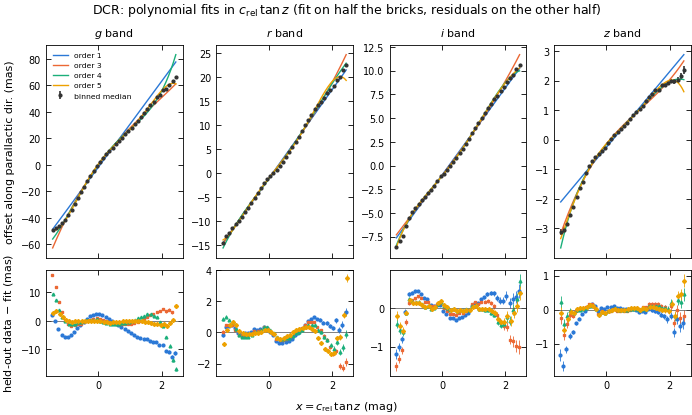

In [4]:
# Figure for Dustin: data (binned medians, all bricks) with each fitted polynomial; below, held-out residuals.
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 4.2), sharex=True, constrained_layout=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for j, b in enumerate(BANDS):
    xc, ym, ye, n = fits[b]['all']
    ax, axr = axes[0, j], axes[1, j]
    ax.errorbar(xc, ym, ye, fmt='o', ms=2, color='0.2', label='binned median')
    xx = np.linspace(xc.min(), xc.max(), 200)
    for k, o in enumerate(ORDERS):
        c = fits[b]['coef'][o]
        ax.plot(xx, np.polyval(c, xx), color=ps.SERIES[k], lw=1, label=f'order {o}')
        xt, yt, et, _ = fits[b]['test']
        axr.errorbar(xt + 0.012 * (k - 1.5), yt - np.polyval(c, xt), et, fmt=ps.MARKERS[k], ms=2,
                     color=ps.SERIES[k], lw=0.6)
    axr.axhline(0, color='0.3', lw=0.5)
    ax.set_title(f'${b}$ band')
    if j == 0:
        ax.set_ylabel('offset along parallactic dir. (mas)')
        axr.set_ylabel('held-out data $-$ fit (mas)')
        ax.legend(fontsize=5.5, loc='upper left')
fig.supxlabel(r'$x = c_{\rm rel}\,\tan z$ (mag)', fontsize=8)
fig.suptitle('DCR: polynomial fits in $c_{\\rm rel}\\,\\tan z$ (fit on half the bricks, residuals on the other half)')
plt.savefig(OUT + 'dcr_polyfit.pdf')

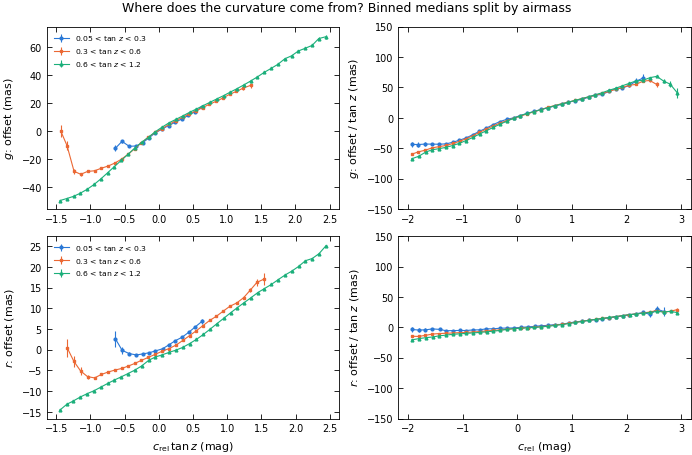

In [5]:
# Diagnostic: is the curvature a function of x = c_rel tan z alone?
# Left: binned medians vs x in three tan z ranges -- overlapping curves mean f(x) is a fair model.
# Right: offset per unit tan z vs c_rel in the same ranges -- overlapping curves mean DCR = tan z * g(c_rel),
# i.e. the non-linearity is in colour (e.g. g-i not tracking the effective wavelength linearly).
TANZ = [(0.05, 0.3), (0.3, 0.6), (0.6, 1.2)]
fig, axes = plt.subplots(2, 2, figsize=(ps.PAGE, 4.6), constrained_layout=True)
for row, b in enumerate(['g', 'r']):
    m = S['band'] == b
    for k, (lo, hi) in enumerate(TANZ):
        s = m & (S['tanz'] > lo) & (S['tanz'] <= hi)
        xc, ym, ye, _ = dcr_fit.binned_medians(S['x'][s], S['y'][s], EDGES, MIN_COUNT)
        axes[row, 0].errorbar(xc, ym, ye, fmt=ps.MARKERS[k] + '-', ms=2, lw=0.8, color=ps.SERIES[k],
                              label=f'{lo} < tan $z$ < {hi}')
        cc, yc, ec, _ = dcr_fit.binned_medians(S['c_rel'][s], S['y'][s] / S['tanz'][s], np.linspace(-2, 3, 41), MIN_COUNT)
        axes[row, 1].errorbar(cc, yc, ec, fmt=ps.MARKERS[k] + '-', ms=2, lw=0.8, color=ps.SERIES[k],
                              label=f'{lo} < tan $z$ < {hi}')
    axes[row, 0].set_ylabel(f'${b}$: offset (mas)')
    axes[row, 1].set_ylabel(f'${b}$: offset / tan $z$ (mas)')
    axes[row, 1].set_ylim(-150, 150)
    axes[row, 0].legend(fontsize=5.5, loc='upper left')
axes[1, 0].set_xlabel(r'$c_{\rm rel}\,\tan z$ (mag)')
axes[1, 1].set_xlabel(r'$c_{\rm rel}$ (mag)')
fig.suptitle('Where does the curvature come from? Binned medians split by airmass')
plt.savefig(OUT + 'dcr_curvature_g_r.pdf')

## Model comparison: polynomial in x vs tan z times polynomial in colour

The diagnostic above shows the curvature is in colour: offset / tan z vs c_rel is nearly the same curve at all
airmasses, while offset vs x is not. So compare, on the held-out bricks, in cells of (c_rel, tan z) -- a test
that can tell the two shapes apart:

- `x`, order n: offset = polynomial of order n in x = c_rel tan z (the meeting suggestion; order 1 = current model)
- `tanz`, order n: offset = tan z x polynomial of order n in c_rel

Metric: weighted RMS (mas) of the held-out cell medians minus the model, over cells with >= 100 epochs.

In [6]:
C_EDGES = np.linspace(-2, 3, 26)
T_EDGES = np.array([0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.3])
models, rows2 = {}, []
for b in BANDS:
    m = S['band'] == b
    tr = dcr_fit.binned_2d(S['c_rel'][m & ~S['test']], S['tanz'][m & ~S['test']], S['y'][m & ~S['test']], C_EDGES, T_EDGES)
    te = dcr_fit.binned_2d(S['c_rel'][m & S['test']], S['tanz'][m & S['test']], S['y'][m & S['test']], C_EDGES, T_EDGES)
    cand = {}
    for o in ORDERS:
        cand[('x', o)] = ('x', np.polyfit(tr[0] * tr[1], tr[2], o, w=1 / tr[3]))
    for o in [1, 2, 3, 4]:
        cand[('tanz', o)] = ('tanz', dcr_fit.fit_tanz_poly(*tr, o))
    models[b] = cand
    w = 1 / te[3]**2
    for name, mod in cand.items():
        r = te[2] - dcr_fit.predict(mod, te[0], te[1])
        rows2.append((b, name, np.sqrt(np.sum(w * r**2) / np.sum(w)), np.sqrt(np.mean(r**2))))
print('band  model          held-out wRMS (mas)   unweighted RMS over cells (mas)')
for b, (kind, o), wr, ur in rows2:
    print(f'  {b}   {kind:4s} order {o}      {wr:6.2f}               {ur:6.2f}')

band  model          held-out wRMS (mas)   unweighted RMS over cells (mas)
  g   x    order 1        2.57                 6.68
  g   x    order 3        1.64                11.43
  g   x    order 4        1.33                 8.04
  g   x    order 5        1.24                14.93
  g   tanz order 1        2.36                 6.47
  g   tanz order 2        1.53                 9.26
  g   tanz order 3        1.51                 8.86
  g   tanz order 4        1.15                 7.02
  r   x    order 1        1.18                 2.27
  r   x    order 3        1.16                 2.51
  r   x    order 4        1.15                 2.84
  r   x    order 5        1.15                 2.44
  r   tanz order 1        0.94                 2.12
  r   tanz order 2        0.63                 1.78
  r   tanz order 3        0.62                 2.62
  r   tanz order 4        0.60                 2.43
  i   x    order 1        0.78                 1.30
  i   x    order 3        0.77           

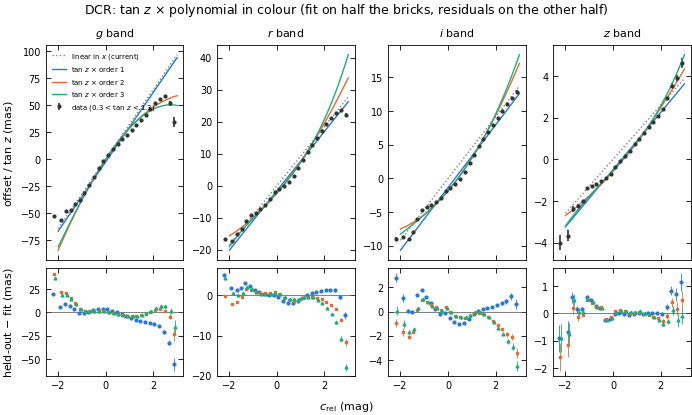

In [7]:
# Figure for Dustin: offset / tan z vs c_rel (data: binned medians of all bricks, in three tan z ranges)
# with tan z x polynomial(c_rel) fits; dashed: the current linear model K_b c_rel. Below: held-out residuals.
SHOW = [1, 2, 3]
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 4.2), sharex=True, constrained_layout=True,
                         gridspec_kw={'height_ratios': [2, 1]})
cc = np.linspace(-2, 3, 200)
for j, b in enumerate(BANDS):
    m = S['band'] == b
    hi_am = m & (S['tanz'] > 0.3) & (S['tanz'] <= 1.3)   # offset / tan z is noisy at small tan z; one airmass cell per colour bin
    a = dcr_fit.binned_2d(S['c_rel'][hi_am], S['tanz'][hi_am], S['y'][hi_am], C_EDGES, np.array([0.3, 1.3]))
    a = a[:, a[1] > 0.3]
    ax, axr = axes[0, j], axes[1, j]
    ax.errorbar(a[0], a[2] / a[1], a[3] / a[1], fmt='o', ms=2, color='0.2', label='data (0.3 < tan $z$ < 1.3)')
    lin = models[b][('x', 1)][1]
    ax.plot(cc, lin[0] * cc, color='0.5', ls=':', lw=1, label='linear in $x$ (current)')
    te = dcr_fit.binned_2d(S['c_rel'][hi_am & S['test']], S['tanz'][hi_am & S['test']], S['y'][hi_am & S['test']], C_EDGES, np.array([0.3, 1.3]))
    te = te[:, te[1] > 0.3]
    for k, o in enumerate(SHOW):
        mod = models[b][('tanz', o)]
        ax.plot(cc, np.polyval(mod[1], cc), color=ps.SERIES[k], lw=1, label=f'tan $z$ × order {o}')
        axr.errorbar(te[0] + 0.03 * (k - 1), (te[2] - dcr_fit.predict(mod, te[0], te[1])) / te[1], te[3] / te[1],
                     fmt=ps.MARKERS[k], ms=2, color=ps.SERIES[k], lw=0.6)
    axr.axhline(0, color='0.3', lw=0.5)
    ax.set_title(f'${b}$ band')
    if j == 0:
        ax.set_ylabel('offset / tan $z$ (mas)')
        axr.set_ylabel('held-out $-$ fit (mas)')
        ax.legend(fontsize=5, loc='upper left')
fig.supxlabel(r'$c_{\rm rel}$ (mag)', fontsize=8)
fig.suptitle('DCR: tan $z$ × polynomial in colour (fit on half the bricks, residuals on the other half)')
plt.savefig(OUT + 'dcr_tanz_polyfit.pdf')

## Two linear fits (James's suggestion)

James saw two regimes ("modes") in the DCR plot. Candidates:
1. **Two stellar populations.** The colours of the calibration stars are bimodal (a blue peak of turnoff stars and
   a red group of K/M dwarfs); g - i may track the effective wavelength differently for each, giving two slopes.
2. **Two airmass regimes.** Northern fields (Dec > ~0) are always seen at tan z ~ 0.8-1 from CTIO, southern fields
   at lower airmass; mixed together in x = c_rel tan z they can look like two branches.

Models (break point fitted on the training bricks, scored on the held-out bricks as before):
- `two`: two independent straight lines in x, for x below / above a break
- `broken`: a continuous broken line in x (two slopes that meet at the break)
- `tanz_broken`: tan z x (broken line in c_rel), i.e. two DCR slopes for blue and red stars

In [8]:
BREAKS_X = np.arange(-0.8, 1.81, 0.05)
BREAKS_C = np.arange(-1.0, 2.01, 0.05)
two = {}
for b in BANDS:
    xt, yt, et, _ = fits[b]['train']
    m = S['band'] == b
    tr2 = dcr_fit.binned_2d(S['c_rel'][m & ~S['test']], S['tanz'][m & ~S['test']], S['y'][m & ~S['test']], C_EDGES, T_EDGES)
    te2 = dcr_fit.binned_2d(S['c_rel'][m & S['test']], S['tanz'][m & S['test']], S['y'][m & S['test']], C_EDGES, T_EDGES)
    two[b] = {'two': dcr_fit.fit_two_lines(xt, yt, et, BREAKS_X),
              'broken': dcr_fit.fit_broken_line(xt, yt, et, BREAKS_X),
              'tanz_broken': dcr_fit.fit_tanz_broken(*tr2, BREAKS_C)}
    w = 1 / te2[3]**2
    xs, ys, es, _ = fits[b]['test']
    w1 = 1 / es**2
    print(f'--- {b} band')
    for name, mod in [('linear in x (current)', models[b][('x', 1)]), ('x order 5', models[b][('x', 5)]),
                      ('two lines in x', two[b]['two']), ('broken line in x', two[b]['broken']),
                      ('tan z x quadratic', models[b][('tanz', 2)]), ('tan z x broken line', two[b]['tanz_broken'])]:
        r2 = te2[2] - dcr_fit.predict_any(mod, te2[0], te2[1])
        r1 = ys - (dcr_fit.predict_any(mod, xs, np.ones_like(xs)) if mod[0] in ('x', 'two', 'broken') else np.nan)
        x_rms = np.sqrt(np.sum(w1 * r1**2) / np.sum(w1)) if mod[0] in ('x', 'two', 'broken') else np.nan
        print(f'  {name:24s} held-out wRMS: binned in x {x_rms:5.2f} mas | in (c_rel, tan z) cells {np.sqrt(np.sum(w * r2**2) / np.sum(w)):5.2f} mas')
    xb, (a0, b0), (a1, b1) = two[b]['two'][1]
    print(f'  two lines: break x = {xb:.2f}; slope below {b0:.2f}, above {b1:.2f} mas/mag')
    cb, a, blo, bhi = two[b]['tanz_broken'][1]
    print(f'  tan z x broken: break c_rel = {cb:.2f}; slope below {blo:.2f}, above {bhi:.2f} mas/mag per unit tan z')

--- g band
  linear in x (current)    held-out wRMS: binned in x  2.51 mas | in (c_rel, tan z) cells  2.57 mas
  x order 5                held-out wRMS: binned in x  0.79 mas | in (c_rel, tan z) cells  1.24 mas
  two lines in x           held-out wRMS: binned in x  0.68 mas | in (c_rel, tan z) cells  1.23 mas
  broken line in x         held-out wRMS: binned in x  0.69 mas | in (c_rel, tan z) cells  1.23 mas
  tan z x quadratic        held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  1.53 mas
  tan z x broken line      held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  1.25 mas
  two lines: break x = -0.05; slope below 40.97, above 25.93 mas/mag
  tan z x broken: break c_rel = 0.10; slope below 39.47, above 24.63 mas/mag per unit tan z


--- r band
  linear in x (current)    held-out wRMS: binned in x  0.42 mas | in (c_rel, tan z) cells  1.18 mas
  x order 5                held-out wRMS: binned in x  0.34 mas | in (c_rel, tan z) cells  1.15 mas
  two lines in x           held-out wRMS: binned in x  0.21 mas | in (c_rel, tan z) cells  1.14 mas
  broken line in x         held-out wRMS: binned in x  0.27 mas | in (c_rel, tan z) cells  1.14 mas
  tan z x quadratic        held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  0.63 mas
  tan z x broken line      held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  0.55 mas
  two lines: break x = 0.15; slope below 9.50, above 10.39 mas/mag
  tan z x broken: break c_rel = 0.75; slope below 8.01, above 13.22 mas/mag per unit tan z


--- i band
  linear in x (current)    held-out wRMS: binned in x  0.25 mas | in (c_rel, tan z) cells  0.78 mas
  x order 5                held-out wRMS: binned in x  0.15 mas | in (c_rel, tan z) cells  0.76 mas
  two lines in x           held-out wRMS: binned in x  0.16 mas | in (c_rel, tan z) cells  0.77 mas
  broken line in x         held-out wRMS: binned in x  0.17 mas | in (c_rel, tan z) cells  0.77 mas
  tan z x quadratic        held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  0.46 mas
  tan z x broken line      held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  0.42 mas
  two lines: break x = 0.15; slope below 4.35, above 5.14 mas/mag
  tan z x broken: break c_rel = 0.50; slope below 3.49, above 6.33 mas/mag per unit tan z


--- z band
  linear in x (current)    held-out wRMS: binned in x  0.14 mas | in (c_rel, tan z) cells  0.51 mas
  x order 5                held-out wRMS: binned in x  0.09 mas | in (c_rel, tan z) cells  0.49 mas
  two lines in x           held-out wRMS: binned in x  0.08 mas | in (c_rel, tan z) cells  0.49 mas
  broken line in x         held-out wRMS: binned in x  0.08 mas | in (c_rel, tan z) cells  0.49 mas
  tan z x quadratic        held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  0.43 mas
  tan z x broken line      held-out wRMS: binned in x   nan mas | in (c_rel, tan z) cells  0.43 mas
  two lines: break x = -0.40; slope below 2.48, above 1.12 mas/mag
  tan z x broken: break c_rel = 0.40; slope below 1.17, above 1.59 mas/mag per unit tan z


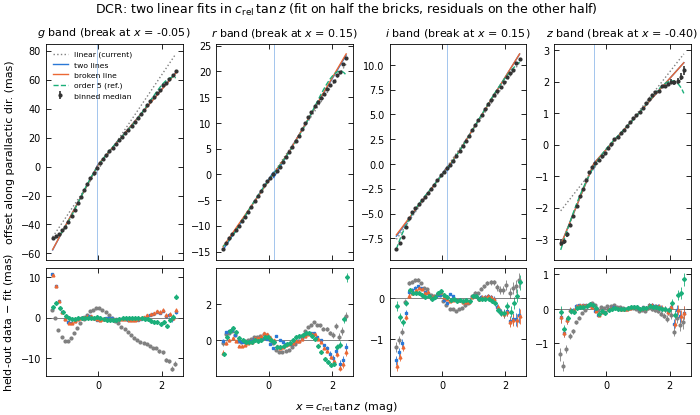

In [9]:
# Figure for James/Dustin: same layout as dcr_polyfit.pdf, with the two-line models.
fig, axes = plt.subplots(2, 4, figsize=(ps.PAGE, 4.2), sharex=True, constrained_layout=True,
                         gridspec_kw={'height_ratios': [2, 1]})
for j, b in enumerate(BANDS):
    xc, ym, ye, n = fits[b]['all']
    ax, axr = axes[0, j], axes[1, j]
    ax.errorbar(xc, ym, ye, fmt='o', ms=2, color='0.2', label='binned median')
    xx = np.linspace(xc.min(), xc.max(), 400)
    cand = [('linear (current)', ('x', fits[b]['coef'][1]), '0.5', ':'),
            ('two lines', two[b]['two'], ps.SERIES[0], '-'),
            ('broken line', two[b]['broken'], ps.SERIES[1], '-'),
            ('order 5 (ref.)', ('x', fits[b]['coef'][5]), ps.SERIES[2], '--')]
    xt, yt, et, _ = fits[b]['test']
    for k, (label, mod, col, ls) in enumerate(cand):
        f = (lambda v: np.polyval(mod[1], v)) if mod[0] == 'x' else (lambda v: dcr_fit.eval_piecewise(mod, v))
        ax.plot(xx, f(xx), color=col, ls=ls, lw=1, label=label)
        axr.errorbar(xt + 0.012 * (k - 1.5), yt - f(xt), et, fmt=ps.MARKERS[k], ms=2, color=col, lw=0.6)
    ax.axvline(two[b]['two'][1][0], color=ps.SERIES[0], lw=0.5, alpha=0.6)
    axr.axhline(0, color='0.3', lw=0.5)
    ax.set_title(f'${b}$ band (break at $x$ = {two[b]["two"][1][0]:.2f})')
    if j == 0:
        ax.set_ylabel('offset along parallactic dir. (mas)')
        axr.set_ylabel('held-out data $-$ fit (mas)')
        ax.legend(fontsize=5.5, loc='upper left')
fig.supxlabel(r'$x = c_{\rm rel}\,\tan z$ (mag)', fontsize=8)
fig.suptitle('DCR: two linear fits in $c_{\\rm rel}\\,\\tan z$ (fit on half the bricks, residuals on the other half)')
plt.savefig(OUT + 'dcr_twolines.pdf')

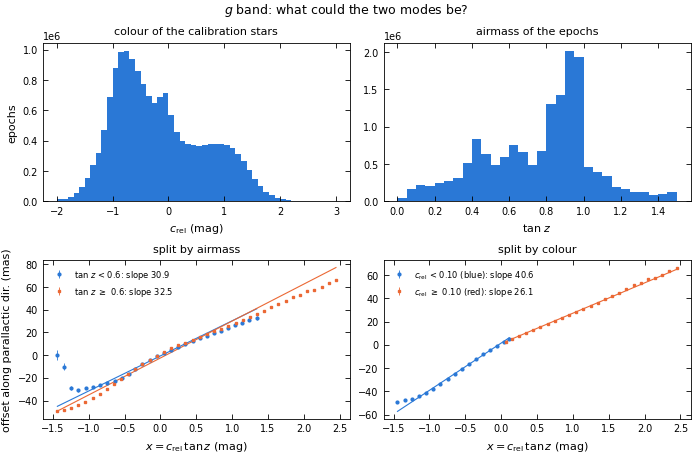

In [10]:
# Figure: the two candidate 'modes' in the g band. Top: distributions of colour and airmass of the calibration
# epochs. Bottom: binned medians vs x split by airmass regime (left) and by colour population (right), each with
# its own straight-line fit -- if a split produces two clearly different slopes, that split is a real 'mode'.
b = 'g'
m = S['band'] == b
fig, axes = plt.subplots(2, 2, figsize=(ps.PAGE, 4.6), constrained_layout=True)
axes[0, 0].hist(S['c_rel'][m], bins=np.arange(-2, 3.01, 0.1), color=ps.SERIES[0])
axes[0, 0].set_xlabel(r'$c_{\rm rel}$ (mag)'); axes[0, 0].set_ylabel('epochs'); axes[0, 0].set_title('colour of the calibration stars')
axes[0, 1].hist(S['tanz'][m], bins=np.arange(0, 1.51, 0.05), color=ps.SERIES[0])
axes[0, 1].set_xlabel('tan $z$'); axes[0, 1].set_title('airmass of the epochs')
CB = two[b]['tanz_broken'][1][0]
for ax, splits, title in [(axes[1, 0], [(S['tanz'] < 0.6, 'tan $z$ < 0.6'), (S['tanz'] >= 0.6, 'tan $z$ $\\geq$ 0.6')], 'split by airmass'),
                          (axes[1, 1], [(S['c_rel'] < CB, f'$c_{{\\rm rel}}$ < {CB:.2f} (blue)'), (S['c_rel'] >= CB, f'$c_{{\\rm rel}}$ $\\geq$ {CB:.2f} (red)')], 'split by colour')]:
    for k, (sel, label) in enumerate(splits):
        s = m & sel
        xc, ym, ye, _ = dcr_fit.binned_medians(S['x'][s], S['y'][s], EDGES, MIN_COUNT)
        c = np.polyfit(xc, ym, 1, w=1 / ye)
        ax.errorbar(xc, ym, ye, fmt=ps.MARKERS[k], ms=2, color=ps.SERIES[k], lw=0.6, label=f'{label}: slope {c[0]:.1f}')
        ax.plot(xc, np.polyval(c, xc), color=ps.SERIES[k], lw=0.8)
    ax.set_xlabel(r'$x = c_{\rm rel}\,\tan z$ (mag)'); ax.set_title(title); ax.legend(fontsize=6, loc='upper left')
axes[1, 0].set_ylabel('offset along parallactic dir. (mas)')
fig.suptitle('$g$ band: what could the two modes be?')
plt.savefig(OUT + 'dcr_two_modes.pdf')